In [1]:
from sklearn.datasets import load_iris


from sklearn import tree


from sklearn.model_selection import train_test_split


import sklearn.metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


import graphviz
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV

import pandas as pd
import numpy as np

In [2]:
iris = load_iris()

# separando treino e teste

In [3]:
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.30)

In [4]:
X_train

array([[6.8, 3.2, 5.9, 2.3],
       [5.4, 3.4, 1.5, 0.4],
       [4.5, 2.3, 1.3, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [6.6, 3. , 4.4, 1.4],
       [5.1, 3.8, 1.6, 0.2],
       [5. , 3.3, 1.4, 0.2],
       [5.8, 2.7, 5.1, 1.9],
       [5.8, 4. , 1.2, 0.2],
       [5.1, 3.4, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.9, 3.2, 4.8, 1.8],
       [6.5, 3. , 5.8, 2.2],
       [6.7, 3.1, 4.4, 1.4],
       [6. , 2.9, 4.5, 1.5],
       [6.5, 2.8, 4.6, 1.5],
       [4.4, 2.9, 1.4, 0.2],
       [6.3, 2.7, 4.9, 1.8],
       [7.2, 3.2, 6. , 1.8],
       [6.7, 3.1, 5.6, 2.4],
       [5.8, 2.7, 3.9, 1.2],
       [5.4, 3. , 4.5, 1.5],
       [5.1, 3.5, 1.4, 0.2],
       [4.6, 3.4, 1.4, 0.3],
       [5.6, 2.9, 3.6, 1.3],
       [5.6, 2.7, 4.2, 1.3],
       [6.1, 2.9, 4.7, 1.4],
       [5.1, 3.3, 1.7, 0.5],
       [5. , 3.5, 1.6, 0.6],
       [5.4, 3.9, 1.3, 0.4],
       [6.1, 3. , 4.6, 1.4],
       [6.1, 2.8, 4. , 1.3],
       [4.8, 3.4, 1.6, 0.2],
       [5.6, 2

# verificando nao nulos

In [5]:
c = {'classes': y_train}
dataset_analysis = pd.DataFrame(data=c)
dataset_analysis.info()
#dataset_analysis.hist()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   classes  105 non-null    int64
dtypes: int64(1)
memory usage: 968.0 bytes


# verificando balanceamento das classes

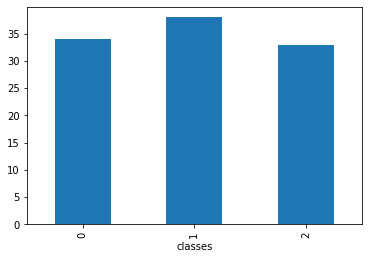

In [6]:
dataset_analysis.groupby('classes')['classes'].count().plot.bar()

# analise exploratoria

Text(0, 0.5, 'Sepal width')

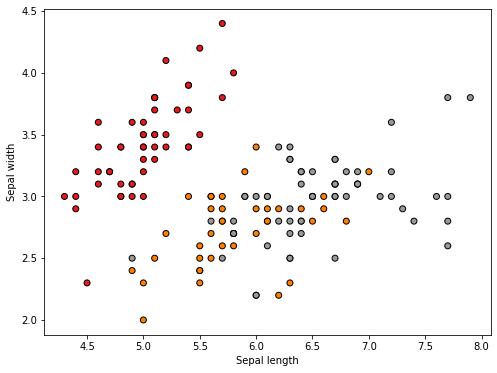

In [7]:
X = iris.data[:, :2]  
y = iris.target

plt.figure(2, figsize=(8, 6))
plt.clf()

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1,edgecolor='k')

plt.xlabel('Sepal length')
plt.ylabel('Sepal width')

a classe de dois tipos de plantas estao se misturando quando olhamos apenas o comprimento da sepa. entao na proxima analise vamos tentar olhar para petala tbm e ver se eh uma feature mais interessante.

Text(0, 0.5, 'Petal width')

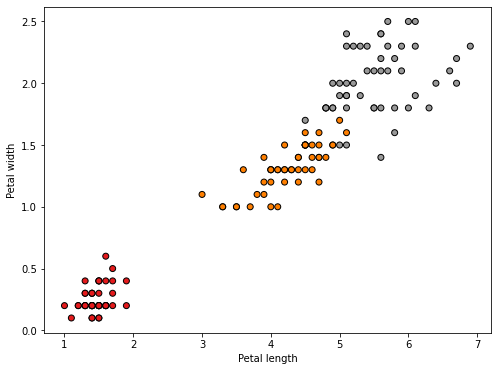

In [8]:
X = iris.data[:, 2:4]
y = iris.target

plt.figure(2, figsize=(8, 6))
plt.clf()

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1,edgecolor='k')

plt.xlabel('Petal length')
plt.ylabel('Petal width')

# arvore de decisao

In [9]:
clf = tree.DecisionTreeClassifier()
clf = clf.fit(X_train.data, y_train)

In [10]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

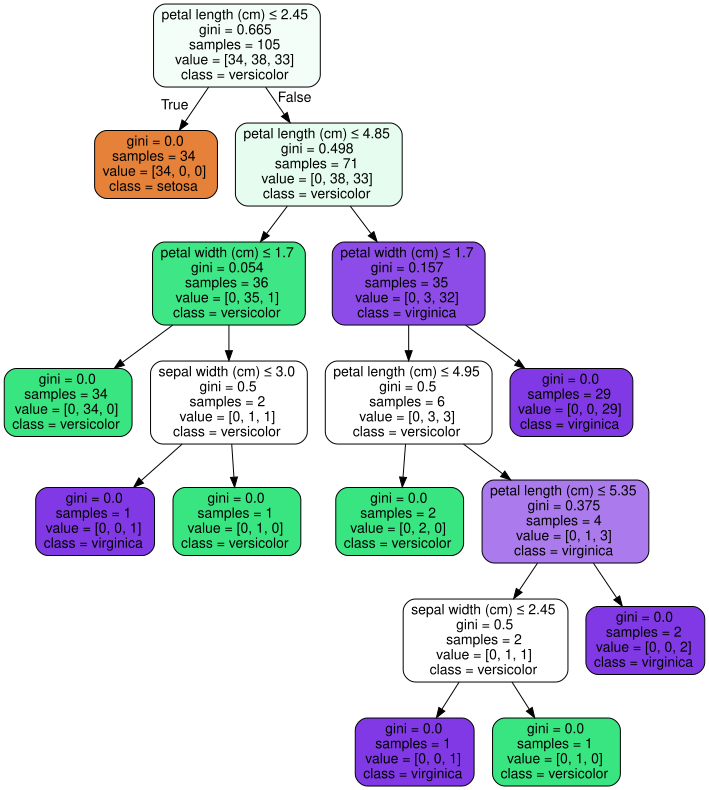

In [11]:
dot_data = tree.export_graphviz(clf, out_file=None, 
                         feature_names=iris.feature_names,  
                         class_names=iris.target_names,  
                         filled=True, rounded=True,  
                         special_characters=True)  
graph = graphviz.Source(dot_data)  
graph


In [12]:
y_pred = clf.predict(X_test.data)
y_pred

array([0, 1, 2, 1, 2, 1, 0, 2, 2, 2, 0, 1, 2, 1, 0, 2, 2, 0, 2, 1, 0, 1,
       2, 2, 1, 0, 2, 0, 0, 2, 0, 2, 1, 0, 0, 2, 1, 0, 0, 1, 2, 2, 0, 0,
       1])

In [13]:
#y_pred = clf.predict_proba([[5.1, 3.5, 1.4, 0.2]])
#y_pred[0]

In [14]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.92      0.92      0.92        12
           2       0.94      0.94      0.94        17

    accuracy                           0.96        45
   macro avg       0.95      0.95      0.95        45
weighted avg       0.96      0.96      0.96        45



In [15]:
print(confusion_matrix(y_test, y_pred))

[[16  0  0]
 [ 0 11  1]
 [ 0  1 16]]


# random forest

In [16]:
from sklearn.ensemble import RandomForestClassifier

clf2=RandomForestClassifier(criterion='gini', n_estimators=100, max_depth=4, bootstrap=True, class_weight='balanced')
clf2.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced', max_depth=4)

In [17]:
y_pred=clf2.predict(X_test)

In [18]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       0.92      0.92      0.92        12
           2       0.94      0.94      0.94        17

    accuracy                           0.96        45
   macro avg       0.95      0.95      0.95        45
weighted avg       0.96      0.96      0.96        45



# Cross-validation: evaluating estimator performance

Learning the parameters of a prediction function and testing it on the same data is a methodological mistake: a model that would just repeat the labels of the samples that it has just seen would have a perfect score but would fail to predict anything useful on yet-unseen data. This situation is called overfitting. To avoid it, it is common practice when performing a (supervised) machine learning experiment to hold out part of the available data as a test set X_test, y_test. Note that the word “experiment” is not intended to denote academic use only, because even in commercial settings machine learning usually starts out experimentally. Here is a flowchart of typical cross validation workflow in model training. The best parameters can be determined by grid search techniques.

https://scikit-learn.org/stable/modules/cross_validation.html

Em outras palavras temos dificuldade pra duas coisas ao fazer um modelo:

* acertar a regulagem dos parametros do modelo para ajustar melhor a curva
* testar com os mesmos dados do teste sabendo que isso pode nos fazer cair numa pegadinha de overfiting

O cross validation é um tecnica de validação do modelo gerado pensando que se fizermos diversos recortes de treino e teste diferentes podemos talvez evitar que o modelo seja erroneamente bem avaliado pq pegou um conjutno de teste que favoreceu o teste. entao ele faz k divisoes do conjunto de treino e teste e testar. Note que o grid search é um complemento dessa técnica para já testar diferentes parametros e testa-los usando cross validation.

In [19]:
#https://gusrabbit.com/code/cross_validate/

#k-fold

from sklearn.model_selection import KFold # import KFold

X = np.array([[1, 2], [3, 4], [1, 2], [3, 4]]) # create an array
y = np.array([1, 2, 3, 4]) # Create another array


kf = KFold(n_splits=2) # Define the split - into 2 folds 
kf.get_n_splits(X) # returns the number of splitting iterations in the cross-validator
print(kf)
KFold(n_splits=2, random_state=None, shuffle=False)

#
for train_index, test_index in kf.split(X):
 print(“TRAIN:”, train_index, “TEST:”, test_index)
 X_train, X_test = X[train_index], X[test_index]
 y_train, y_test = y[train_index], y[test_index]
('TRAIN:', array([2, 3]), 'TEST:', array([0, 1]))
('TRAIN:', array([0, 1]), 'TEST:', array([2, 3]))


# Leave One Out - alto custo computacional pq k eh igual o numero de amostras e deve ser usado com conjuntos de dados pequenos

from sklearn.model_selection import LeaveOneOut 
X = np.array([[1, 2], [3, 4]])
y = np.array([1, 2])
loo = LeaveOneOut()
loo.get_n_splits(X)


for train_index, test_index in loo.split(X):
   print('TRAIN:', train_index, "TEST:", test_index)
   X_train, X_test = X[train_index], X[test_index]
   y_train, y_test = y[train_index], y[test_index]
   print(X_train, X_test, y_train, y_test)
    
('TRAIN:', array([1]), 'TEST:', array([0]))
(array([[3, 4]]), array([[1, 2]]), array([2]), array([1]))
('TRAIN:', array([0]), 'TEST:', array([1]))
(array([[1, 2]]), array([[3, 4]]), array([1]), array([2]))


SyntaxError: ignored

# grid search - busca para otimização dos hyperparametros

In [ ]:
# https://gusrabbit.com/code/grid-search/
        
param_grid = { 
    'n_estimators': [200, 500],
    'max_features': ['auto', 'sqrt', 'log2'],
    'max_depth' : [4,5,6,7,8],
    'criterion' :['gini', 'entropy']
}

rfc = RandomForestClassifier()

CV_rfc = GridSearchCV(estimator=rfc, param_grid=param_grid, cv= 5)
CV_rfc.fit(X_train,y_train)

In [ ]:
print(CV_rfc.best_params_)

Cross-validation is when you reserve part of your data to use in evaluating your model. There are different cross-validation methods. The simplest conceptually is to just take 70% (just making up a number here, it doesn't have to be 70%) of your data and use that for training, and then use the remaining 30% of the data to evaluate the model's performance. The reason you need different data for training and evaluating the model is to protect against overfitting. There are other (slightly more involved) cross-validation techniques, of course, like k-fold cross-validation, which often used in practice.

Grid search is a method to perform hyper-parameter optimisation, that is, it is a method to find the best combination of hyper-parameters (an example of an hyper-parameter is the learning rate of the optimiser), for a given model (e.g. a CNN) and test dataset. In this scenario, you have several models, each with a different combination of hyper-parameters. Each of these combinations of parameters, which correspond to a single model, can be said to lie on a point of a "grid". The goal is then to train each of these models and evaluate them e.g. using cross-validation. You then select the one that performed best.

Cross-validation is a method for robustly estimating test-set performance (generalization) of a model. Grid-search is a way to select the best of a family of models, parametrized by a grid of parameters.

Here, by "model", I don't mean a trained instance, more the algorithms together with the parameters, such as SVC(C=1, kernel='poly').

Cross-validation, simply separating test and training data and validate training results with test data. There are two cross validation techniques that I know.

First, Test/Train cross validation. Splitting data as test and train.

Second, k-fold cross-validation split your data into k bins, use each bin as testing data and use rest of the data as training data and validate against testing data. Repeat the process k times. And Get the average performance. k-fold cross validation especially useful for small dataset since it maximizes both the test and training data.

Grid Search; systematically working through multiple combinations of parameter tunes, cross validate each and determine which one gives the best performance.You can work through many combination only changing parameters a bit.


Cross-validation is a method of reserving a particular subset of your dataset on which you do not train the model. Later, you test your model on this subset before finalizing it.

The main steps you need to perform to do cross-validation are:

Split the whole dataset in training and test datasets (e.g. 80% of the whole dataset is the training dataset and the remaining 20% is the test dataset)

Train the model using the training dataset

Test your model on the test dataset. If your model performs well on the test dataset, continue the training process

There are other cross-validation methods, for example

Leave-one-out cross-validation (LOOCV)

K-fold cross-validation

Stratified K-fold cross-validation

Adversarial cross-validation strategies (used when train and rest datasets are differ largely from each other).

# HYPEROPT

In [ ]:
#HYPEROPT - https://www.automl.org/wp-content/uploads/2018/12/hyperopt-sklearn-1.pdf

# Trabalhando com dados desbalanceados

SMOTE

https://towardsdatascience.com/17-types-of-similarity-and-dissimilarity-measures-used-in-data-science-3eb914d2681

# gradient boosting

# XGB

In [ ]:
# https://www.kaggle.com/tunguz/xgb-gpu-hyperparameters-with-optuna

# KNN

In [ ]:
dados_petalas = pd.DataFrame({'comprimento': iris.data[:,2], 'largura': iris.data[:,3], 'tipo': iris.target})
dados_petalas.head()

In [ ]:
plt.figure(2, figsize=(8, 6))
plt.scatter(dados_petalas['largura'], dados_petalas['comprimento'], c=dados_petalas['tipo'])
plt.xlabel('largura petala')
plt.ylabel('comprimento petala')

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(dados_petalas[["comprimento","largura"]],
                                                    dados_petalas["tipo"],
                                                    test_size=0.33, random_state=42)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier 
knncf = KNeighborsClassifier(n_neighbors=3)
knncf.fit(X_train,y_train)

In [ ]:
result = knncf.predict(X_test)

In [ ]:
print(classification_report(y_test, result))

SMOTE - um knn para tratar classes desbalanceadas (https://towardsdatascience.com/5-smote-techniques-for-oversampling-your-imbalance-data-b8155bdbe2b5)

# regressao logistica

https://www.youtube.com/watch?v=yIYKR4sgzI8&t=309s


a regressao logistica e similar a regressao linear, mas ao inves de fitar uma reta nos dados ela tenta encontrar um curva em forma de S na qual o dados pertecentes a uma classe ficam no topo dessa curva e os dados pertencentes a outra ficam na parte inferior do S. A ideia que o topo da curva representa o valor 1 e a parte inferior o 1, como na funcao sigmoide. o que a funcao logit faz eh forcar o y de resutado ser jogado pra 0 ou 1, representando a probabilidade de se da classe 0 ou 1 (true ou false) e por isso eh melhor aplicada para problemas de classificao binária. para ajustar a funcao logisca com S encima dos dados eh usado o metodo da maxima verossimilhanca (likelihood) que vai calculando e descolando a curva ateh o melhor fit, sendo que a avaliacao do fit dessa curva tbm usa o R quadrado (coeficiente de determinacao para analise de ruidos).

https://www.youtube.com/watch?v=vN5cNN2-HWE&t=995s

In [ ]:
plantas1e2 = dados_petalas.loc[ (dados_petalas['tipo']==1) | (dados_petalas['tipo']==2) ]
plt.scatter(plantas1e2['comprimento'], plantas1e2['largura'], c=plantas1e2['tipo'])
plt.suptitle('apenas as classes 1 e 2 filtradas com loc no df')
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(plantas1e2[["comprimento","largura"]],
                                                    plantas1e2["tipo"],
                                                    test_size=0.33, random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(random_state=0).fit(X_train, y_train)

In [ ]:
print(clf.predict_proba([[4,1.4]]))

In [ ]:
resultado_classificacao = clf.predict(X_test)

In [ ]:
print(classification_report(y_test, resultado_classificacao))

In [ ]:
from scipy.special import expit

plt.figure(1, figsize=(4, 3))
plt.clf()
#plt.scatter(X_train, y_train, color='black', zorder=20)

loss = expit(X_test * clf.coef_ + clf.intercept_).ravel()
plt.plot(X_test, loss, color='red', linewidth=3)

# SVM

In [ ]:
#https://scikit-learn.org/stable/modules/svm.html

# clusterizacao - k means

# PCA

In [ ]:
https://www.youtube.com/watch?v=FgakZw6K1QQ
https://www.youtube.com/watch?v=HMOI_lkzW08

In [ ]:
#pandas.get_dummies

# one hot encode - gera os targets em colunas diferentes
# In machine learning, one-hot encoding is a frequently used method to deal with categorical data.

# using ordinal encoding can potentially create a fictional ordinal relationship in the data.
#Therefore, one-hot encoding is often applied to nominal variables, in order to improve the performance of the algorithm.

pd.get_dummies(dataset['tipo'])

# regressao

In [ ]:
plt.figure(2, figsize=(8, 6))
plt.scatter(dados_petalas['largura'], dados_petalas['comprimento'])
plt.xlabel('largura petala')
plt.ylabel('comprimento petala')

In [ ]:
from matplotlib.collections import LineCollection
from sklearn.linear_model import LinearRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.utils import check_random_state
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(dados_petalas['largura'].values.reshape(-1, 1),
                                                    dados_petalas['comprimento'].values,
                                                    test_size=0.2, random_state=0)

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)
print("coeficiente angular da reta de regressao ", lr.coef_)
print("coeficiente liner da reta ", lr.intercept_)

In [ ]:
plt.figure(2, figsize=(8, 6))

plt.scatter(dados_petalas['largura'], dados_petalas['comprimento'])

plt.plot(X_train, lr.predict(X_train), color='red')

plt.xlabel('largura petala')
plt.ylabel('comprimento petala')

plt.show()

In [ ]:
larg = 0.7
comprimento_dado_largura = lr.predict([[larg]])
print('o comprimento de uma petala com', larg, 'de largura seria: ', comprimento_dado_largura)

In [ ]:
y_pred = lr.predict(X_test)

In [ ]:
print("MSE: ", mean_squared_error(y_test,y_pred))
print('Coefficient of determination - r2:', r2_score(y_test, y_pred))

# regularizacao

# arvore de regressao